# 1. 数据预处理

In [199]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/processed_data.csv')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,cancelled
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False


In [200]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 401604 entries, 0 to 401603
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    401604 non-null  str    
 1   StockCode    401604 non-null  str    
 2   Description  401604 non-null  str    
 3   Quantity     401604 non-null  int64  
 4   InvoiceDate  401604 non-null  str    
 5   UnitPrice    401604 non-null  float64
 6   CustomerID   401604 non-null  int64  
 7   Country      401604 non-null  str    
 8   TotalPrice   401604 non-null  float64
 9   cancelled    401604 non-null  bool   
dtypes: bool(1), float64(2), int64(2), str(5)
memory usage: 28.0 MB


In [201]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%Y-%m-%d %H:%M:%S')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 401604 entries, 0 to 401603
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401604 non-null  str           
 1   StockCode    401604 non-null  str           
 2   Description  401604 non-null  str           
 3   Quantity     401604 non-null  int64         
 4   InvoiceDate  401604 non-null  datetime64[us]
 5   UnitPrice    401604 non-null  float64       
 6   CustomerID   401604 non-null  int64         
 7   Country      401604 non-null  str           
 8   TotalPrice   401604 non-null  float64       
 9   cancelled    401604 non-null  bool          
dtypes: bool(1), datetime64[us](1), float64(2), int64(2), str(4)
memory usage: 28.0 MB


In [202]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalPrice
count,401604.000000,401604,401604.000000,401604.000000,401604.000000
mean,12.183273,2011-07-10 12:08:23.848567,3.474064,15281.160818,23.644930
min,-80995.000000,2010-12-01 08:26:00,0.000000,12346.000000,0.000000
25%,2.000000,2011-04-06 15:02:00,1.250000,13939.000000,4.950000
50%,5.000000,2011-07-29 15:40:00,1.950000,15145.000000,11.900000
75%,12.000000,2011-10-20 11:58:30,3.750000,16784.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,168469.600000
std,250.283037,NaN,69.764035,1714.006089,430.196317


In [203]:
# 设置R，使用九十天前的日期作为参考日期，为后续机器学习建模做准备
analysis_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
reference_date = analysis_date - pd.Timedelta(days=90)
reference_date

Timestamp('2011-09-11 12:50:00')

In [204]:
df = df[df['InvoiceDate'] <= reference_date]
df['InvoiceDate'].max()

Timestamp('2011-09-11 12:46:00')

In [205]:
rfm = df.groupby('CustomerID').agg(
    last_purchase_date=('InvoiceDate', 'max'),
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

rfm.columns = ['CustomerID', 'last_purchase_date', 'Recency', 'Frequency', 'Monetary']
rfm.head()

,CustomerID,last_purchase_date,Recency,Frequency,Monetary
0,12346,2011-01-18 10:17:00,236,2,154367.20
1,12347,2011-08-02 08:48:00,40,5,2790.86
2,12348,2011-04-05 10:47:00,159,3,1487.24
3,12350,2011-02-02 16:01:00,220,1,334.40
4,12352,2011-03-22 16:08:00,172,8,2522.44


In [206]:
rfm.describe()

,CustomerID,last_purchase_date,Recency,Frequency,Monetary
count,3418.000000,3418,3418.000000,3418.000000,3418.000000
mean,15275.588063,2011-06-08 18:00:32.422469,94.273844,4.224985,1692.262236
min,12346.000000,2010-12-01 09:53:00,0.000000,1.000000,1.250000
25%,13784.500000,2011-04-12 16:33:15,24.000000,1.000000,260.252500
50%,15234.500000,2011-06-30 13:50:30,72.000000,2.000000,571.780000
75%,16766.750000,2011-08-17 15:01:00,151.000000,5.000000,1402.762500
max,18287.000000,2011-09-11 12:46:00,284.000000,139.000000,179019.620000
std,1727.089087,NaN,80.938314,7.094990,6860.444320


# 2. 分位数划分客户群体

In [207]:
# 设置RFM评分
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

def customer_segment(row):
    r = row['R_Score']
    f = row['F_Score']
    m = row['M_Score']

    if r >= 4 and f >= 4 and m >= 4:
        return 'High-Value Customers'
    elif r >= 4 and f >= 4 and m <= 3:
        return 'Potential Loyalists'
    elif r >= 4 and f <= 3 and m >= 4:
        return 'Big Spenders'
    elif r >= 4 and f <= 3 and m <= 3:
        return 'New Customers'
    elif r <= 3 and f >= 4 and m >= 4:
        return 'Loyal Customers'
    elif r <= 3 and f >= 4 and m <= 3:
        return 'Regular Customers'
    elif r <= 3 and f <= 3 and m >= 4:
        return 'At-Risk High Spenders'
    else:
        return 'Lost or Dormant Customers'

rfm['Customer_Segment'] = rfm.apply(customer_segment, axis=1)
rfm.head()

,CustomerID,last_purchase_date,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,12346,2011-01-18 10:17:00,236,2,154367.20,1,2,5,125,At-Risk High Spenders
1,12347,2011-08-02 08:48:00,40,5,2790.86,4,4,5,445,High-Value Customers
2,12348,2011-04-05 10:47:00,159,3,1487.24,2,3,4,234,At-Risk High Spenders
3,12350,2011-02-02 16:01:00,220,1,334.40,1,1,2,112,Lost or Dormant Customers
4,12352,2011-03-22 16:08:00,172,8,2522.44,1,5,5,155,Loyal Customers


In [208]:
# 比较各群体的 R、F、M 均值、中位数和客户数量。
rfm.groupby('Customer_Segment').agg({
    'Recency': ['mean', 'median', 'count'],
    'Frequency': ['mean', 'median', 'count'],
    'Monetary': ['mean', 'median', 'count']
}).reset_index()

Customer_Segment     Recency               Frequency               \
                                    mean median count       mean median count   
0      At-Risk High Spenders  131.769634  118.0   191   1.968586    2.0   191   
1               Big Spenders   22.045455   21.0   110   2.145455    2.0   110   
2       High-Value Customers   18.344327   16.0   758  11.006596    8.0   758   
3  Lost or Dormant Customers  160.150365  157.0  1370   1.371533    1.0  1370   
4            Loyal Customers   95.029221   84.5   308   5.798701    5.0   308   
5              New Customers   23.102632   22.0   380   1.610526    2.0   380   
6        Potential Loyalists   23.041667   22.5   120   4.100000    4.0   120   
7          Regular Customers  113.320442   97.0   181   3.961326    4.0   181   

      Monetary                  
          mean    median count  
0  2238.629586  1140.000   191  
1  1586.922545  1204.305   110  
2  4924.419670  2238.510   758  
3   287.326401   252.650  1370  
4  2458.364643  1488.310   308  
5   365.207526   337.590   380  
6   554.724258   603.350   120  
7   514.603481   548.310   181

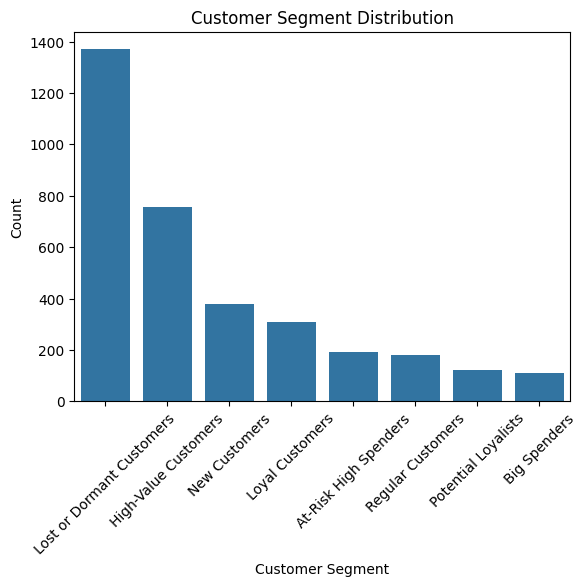

In [209]:
# 统计不同群体的数量
import matplotlib.pyplot as plt 
import seaborn as sns

segment_counts = rfm['Customer_Segment'].value_counts()
sns.barplot(x=segment_counts.index, y=segment_counts.values)
plt.xlabel('Customer Segment')
plt.xticks(rotation=45)
plt.ylabel('Count')
plt.title('Customer Segment Distribution')
plt.show()

# 3. 聚类划分客户群体

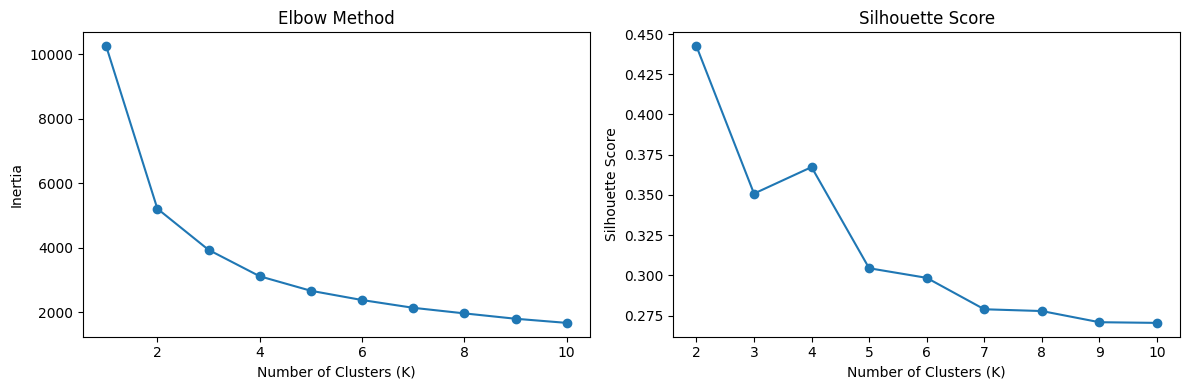

In [210]:
# 使用K-Means聚类进行客户分群
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 选择RFM特征进行聚类
scaler = StandardScaler()
rfm[['Recency', 'Frequency', 'Monetary']] = rfm[['Recency', 'Frequency', 'Monetary']].apply(np.log1p)
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])

sse = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfm_scaled)
    sse.append(kmeans.inertia_)

sil_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    sil_scores.append(score)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, 11), sse, marker='o')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')

axes[1].plot(range(2, 11), sil_scores, marker='o')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score')

plt.tight_layout()
plt.show()

从图上可以看出，在k=4时，聚类效果最好

In [211]:
k = 4
kmeans = KMeans(n_clusters=k, random_state=42)
labels = kmeans.fit_predict(rfm_scaled)
rfm['Cluster'] = labels

persona_map = {
    0: 'At-Risk Customers',
    1: 'Loyal Customers',
    2: 'Big Spenders',
    3: 'Regular Customers'
}

rfm['Persona'] = rfm['Cluster'].map(persona_map)
rfm.head()

,CustomerID,last_purchase_date,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment,Cluster,Persona
0,12346,2011-01-18 10:17:00,5.468060,1.098612,11.947096,1,2,5,125,At-Risk High Spenders,0,At-Risk Customers
1,12347,2011-08-02 08:48:00,3.713572,1.791759,7.934463,4,4,5,445,High-Value Customers,0,At-Risk Customers
2,12348,2011-04-05 10:47:00,5.075174,1.386294,7.305349,2,3,4,234,At-Risk High Spenders,0,At-Risk Customers
3,12350,2011-02-02 16:01:00,5.398163,0.693147,5.815324,1,1,2,112,Lost or Dormant Customers,1,Loyal Customers
4,12352,2011-03-22 16:08:00,5.153292,2.197225,7.833378,1,5,5,155,Loyal Customers,0,At-Risk Customers


In [212]:
# 比较各群体的 R、F、M 均值、中位数和客户数量。
rfm.groupby('Cluster').agg({
    'Recency': ['mean', 'median', 'count'],
    'Frequency': ['mean', 'median', 'count'],
    'Monetary': ['mean', 'median', 'count']
}).reset_index()

Cluster   Recency                 Frequency                  Monetary  \
               mean    median count      mean    median count      mean   
0       0  4.226833  4.219508  1014  1.563099  1.609438  1014  7.026548   
1       1  4.933960  5.056246  1436  0.823422  0.693147  1436  5.395194   
2       2  2.365153  2.397895   488  2.564728  2.397895   488  8.285401   
3       3  2.414273  2.639057   480  1.165237  1.098612   480  6.216160   

                   
     median count  
0  6.980391  1014  
1  5.483655  1436  
2  8.095187   488  
3  6.279322   480

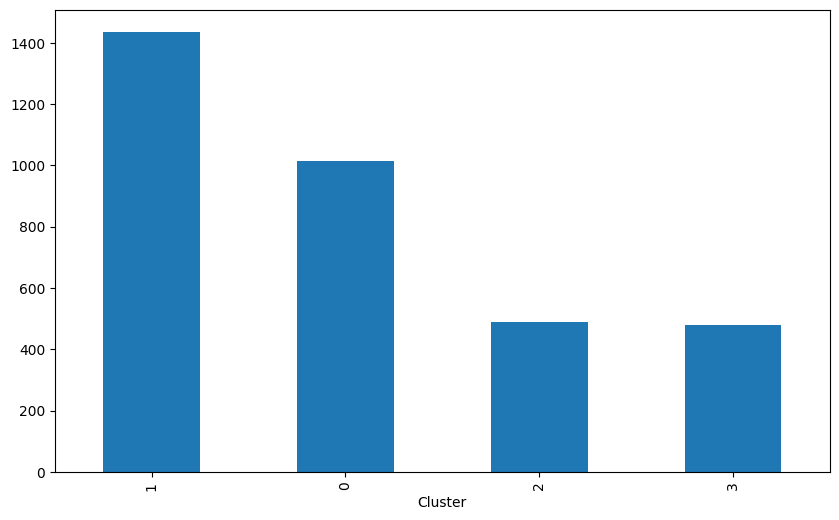

In [213]:
# 计算各群体客户占比
rfm['Cluster'].value_counts().plot(kind='bar', figsize=(10, 6))
plt.show()

# 4. 两种划分方式的对比

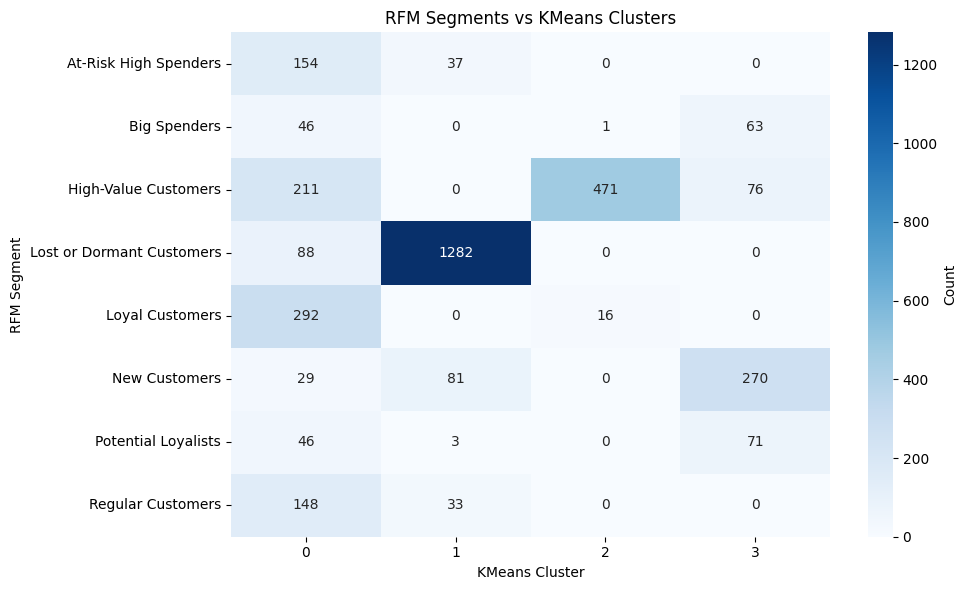

In [214]:
# 比较两种分组方式的客户特征
crosstab = pd.crosstab(rfm['Customer_Segment'], rfm['Cluster'])

plt.figure(figsize=(10, 6))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Count'})
plt.title('RFM Segments vs KMeans Clusters')
plt.xlabel('KMeans Cluster')
plt.ylabel('RFM Segment')
plt.tight_layout()
plt.show()

In [215]:
# 检验两种分组方式的关联性
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(crosstab)
print(f"p-value: {p}")
if p < 0.05:
    print("两种分组方式存在显著关联")
else:
    print("两种分组方式相互独立")

p-value: 0.0
两种分组方式存在显著关联


In [216]:
rfm.head()

,CustomerID,last_purchase_date,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment,Cluster,Persona
0,12346,2011-01-18 10:17:00,5.468060,1.098612,11.947096,1,2,5,125,At-Risk High Spenders,0,At-Risk Customers
1,12347,2011-08-02 08:48:00,3.713572,1.791759,7.934463,4,4,5,445,High-Value Customers,0,At-Risk Customers
2,12348,2011-04-05 10:47:00,5.075174,1.386294,7.305349,2,3,4,234,At-Risk High Spenders,0,At-Risk Customers
3,12350,2011-02-02 16:01:00,5.398163,0.693147,5.815324,1,1,2,112,Lost or Dormant Customers,1,Loyal Customers
4,12352,2011-03-22 16:08:00,5.153292,2.197225,7.833378,1,5,5,155,Loyal Customers,0,At-Risk Customers


In [217]:
rfm.to_csv('data/rfm.csv', index=False)